# Exercitiul 1

**a)** $A\perp C\mid B$: daca stim B, cunoasterea lui C nu mai schimba
probabilitatea lui A:

$$P(a\mid b,c)=P(a\mid b).$$

**b)** Din independenta conditionata:

$$P(a,b,c)=P(a,c\mid b)P(b)=P(a\mid b)P(c\mid b)P(b).$$

Alegem:

$$\phi_{AB}(a,b)=P(a\mid b)P(b),\qquad
\phi_{BC}(b,c)=P(c\mid b),\qquad Z=1.$$

Atunci $P(a,b,c)=Z^{-1}\phi_{AB}(a,b)\phi_{BC}(b,c)$.
Potentialele sunt strict pozitive deoarece distributia este strict pozitiva.

**c)** Presupunem factorizarea si notam:

$$U(b)=\sum_a\phi_{AB}(a,b),\qquad
V(b)=\sum_c\phi_{BC}(b,c).$$

Insumand dupa a si c:

$$P(b)=Z^{-1}U(b)V(b).$$

Prin urmare:

$$P(a,c\mid b)=\frac{P(a,b,c)}{P(b)}
=\frac{\phi_{AB}(a,b)}{U(b)}\frac{\phi_{BC}(b,c)}{V(b)}.$$

Insumand dupa c, respectiv dupa a:

$$P(a\mid b)=\frac{\phi_{AB}(a,b)}{U(b)},\qquad
P(c\mid b)=\frac{\phi_{BC}(b,c)}{V(b)}.$$

Rezulta $P(a,c\mid b)=P(a\mid b)P(c\mid b)$, deci $A\perp C\mid B$.

# Exercitiul 2

**a)** Alegem arborele S1 - S2 - S3 - S4. Vecinii sunt:
S1: S2; S2: S1, S3; S3: S2, S4; S4: S3.
Graful este conex, cu 4 noduri si 3 muchii, deci nu are cicluri.

**b-c)** Starile sunt 0 = Soare, 1 = Ploaie, 2 = Nori.
Fiecare factor unar are valorile (0.5, 0.3, 0.2).
Factorul pereche este matricea Psi din enunt, cu primul argument
statia cu indice mai mic. Psi nu este o probabilitate conditionata.

$$P(s_1,s_2,s_3,s_4)=\frac{1}{Z}
\prod_{i=1}^{4}p(s_i)\,
\Psi_{s_1,s_2}\Psi_{s_2,s_3}\Psi_{s_3,s_4}.$$

Z este suma produselor peste toate cele 81 de configuratii.
Factorii unari sunt preferinte initiale, nu neaparat marginalele finale.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.inference import VariableElimination

**b-c) Construirea modelului si afisarea grafului**

Model valid: True
Este arbore: True
Vecinii lui S1 : ['S2']
Vecinii lui S2 : ['S1', 'S3']
Vecinii lui S3 : ['S2', 'S4']
Vecinii lui S4 : ['S3']


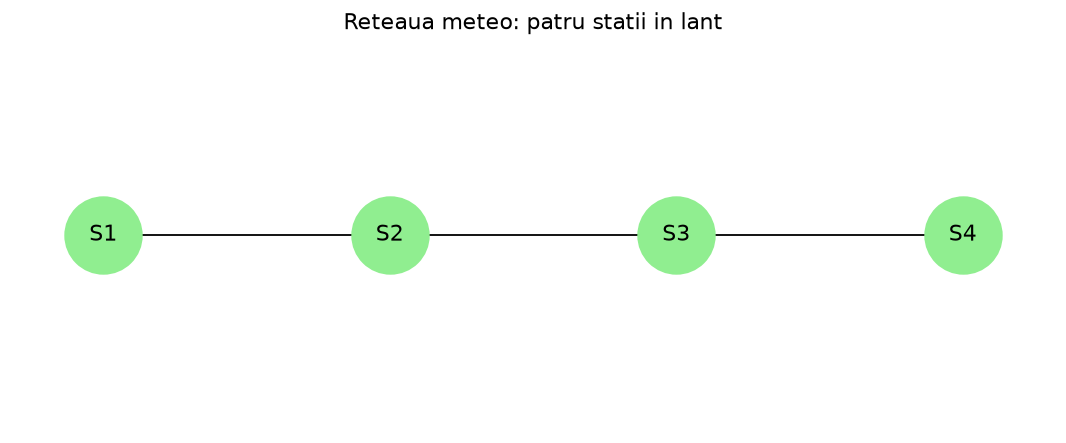

In [2]:
stari = ["Soare", "Ploaie", "Nori"]
statii = ["S1", "S2", "S3", "S4"]
muchii = [("S1", "S2"), ("S2", "S3"), ("S3", "S4")]
probabilitati = [0.5, 0.3, 0.2]
psi = [[0.7, 0.2, 0.1],
       [0.2, 0.6, 0.2],
       [0.1, 0.3, 0.6]]

model = DiscreteMarkovNetwork(muchii)

for statie in statii:
    factor = DiscreteFactor([statie], [3], probabilitati)
    model.add_factors(factor)

for prima, a_doua in muchii:
    factor = DiscreteFactor([prima, a_doua], [3, 3], psi)
    model.add_factors(factor)

print("Model valid:", model.check_model())
print("Este arbore:", nx.is_tree(model))
for statie in statii:
    print("Vecinii lui", statie, ":", list(model.neighbors(statie)))

pozitii = {"S1": (0, 0), "S2": (1, 0),
           "S3": (2, 0), "S4": (3, 0)}
plt.figure(figsize=(8, 3))
nx.draw(model, pos=pozitii, with_labels=True, node_color="lightgreen",
        node_size=1800, font_size=12)
plt.title("Reteaua meteo: patru statii in lant")
plt.show()

**d)** Observam S1 = Soare si S4 = Nori. Calculam marginalele la S2 si S3 si alegem starea cu probabilitatea maxima.

In [3]:
observatii = {"S1": 0, "S4": 2}
inferenta = VariableElimination(model)
maxime_marginale = []

print("Observatii: S1 = Soare, S4 = Nori")
for statie in ["S2", "S3"]:
    rezultat = inferenta.query(variables=[statie], evidence=observatii,
                               show_progress=False)

    rezultat.normalize()
    print("\nDistributia la", statie)
    for stare in range(3):
        print(stari[stare], ":", round(float(rezultat.values[stare]), 6))
    stare_maxima = int(np.argmax(rezultat.values))
    maxime_marginale.append(stare_maxima)
    print("MAP marginal:", stari[stare_maxima])

Observatii: S1 = Soare, S4 = Nori

Distributia la S2
Soare : 0.771963
Ploaie : 0.157009
Nori : 0.071028
MAP marginal: Soare

Distributia la S3
Soare : 0.484112
Ploaie : 0.251215
Nori : 0.264673
MAP marginal: Soare


**e)** Pentru MAP comun comparam toate cele noua perechi (S2, S3).

In [4]:
ponderi = np.zeros((3, 3))

for s2 in range(3):
    for s3 in range(3):
        pondere = (probabilitati[0] * probabilitati[s2]
                   * probabilitati[s3] * probabilitati[2])
        pondere = pondere * psi[0][s2] * psi[s2][s3] * psi[s3][2]
        ponderi[s2, s3] = pondere

total = np.sum(ponderi)
cea_mai_mare = -1
map_comun = []

for s2 in range(3):
    for s3 in range(3):
        probabilitate = ponderi[s2, s3] / total
        print("S2 =", stari[s2], ", S3 =", stari[s3],
              ":", round(float(probabilitate), 6))
        if probabilitate > cea_mai_mare:
            cea_mai_mare = probabilitate
            map_comun = [s2, s3]

print("\nMAP comun: S2 =", stari[map_comun[0]],
      ", S3 =", stari[map_comun[1]])
print("Probabilitatea configuratiei MAP:", round(float(cea_mai_mare), 6))
print("Coincid in acest exemplu:", map_comun == maxime_marginale)

for index, statie in enumerate(["S2", "S3"]):
    rezultat = inferenta.query(variables=[statie], evidence=observatii,
                               show_progress=False)
    rezultat.normalize()
    marginala = np.sum(ponderi, axis=1 - index) / total
    assert np.allclose(marginala, rezultat.values)
    print("Verificare prin enumerare", statie, ":",
          np.allclose(marginala, rezultat.values))

S2 = Soare , S3 = Soare : 0.457944
S2 = Soare , S3 = Ploaie : 0.157009
S2 = Soare , S3 = Nori : 0.157009
S2 = Ploaie , S3 = Soare : 0.02243
S2 = Ploaie , S3 = Ploaie : 0.080748
S2 = Ploaie , S3 = Nori : 0.053832
S2 = Nori , S3 = Soare : 0.003738
S2 = Nori , S3 = Ploaie : 0.013458
S2 = Nori , S3 = Nori : 0.053832

MAP comun: S2 = Soare , S3 = Soare
Probabilitatea configuratiei MAP: 0.457944
Coincid in acest exemplu: True
Verificare prin enumerare S2 : True
Verificare prin enumerare S3 : True


| Statie | Soare | Ploaie | Nori | MAP marginal |
|---|---:|---:|---:|---|
| S2 | 0.771963 | 0.157009 | 0.071028 | Soare |
| S3 | 0.484112 | 0.251215 | 0.264673 | Soare |

MAP comun este **(S2, S3) = (Soare, Soare)**, cu probabilitate 0.457944.
In acest exemplu coincide cu maximele marginale, dar nu intotdeauna.

Contraexemplu separat pentru doua variabile binare:

| | V = 0 | V = 1 |
|---|---:|---:|
| U = 0 | 0.35 | 0.30 |
| U = 1 | 0.01 | 0.34 |

Maximele marginale aleg (0, 1), deoarece P(U = 0) = 0.65 si P(V = 1) = 0.64.
MAP comun este (0, 0), cu probabilitate 0.35 > 0.30.

# Exercitiul 3

**a-b)** Folosim un patrat alb 3 x 3 pe fond negru 5 x 5.
Inversam 3 pixeli din 25 (12%, aproximativ 10%), cu samanta 42.

**c)** Graful leaga fiecare pixel de vecinii directi, fara diagonale:
25 de noduri si 40 de muchii.

$$E(x;y)=\lambda\sum_i(x_i-y_i)^2+
\sum_{(i,j)\in E}(x_i-x_j)^2.$$

Primul termen penalizeaza modificarile fata de observatie;
al doilea penalizeaza vecinii diferiti.

$$\phi_i(x_i)=e^{-\lambda(x_i-y_i)^2},\qquad
\phi_{ij}(x_i,x_j)=e^{-(x_i-x_j)^2}.$$

$$P(x\mid y)=\frac{1}{Z(y)}e^{-E(x;y)}.$$

Maximizarea probabilitatii este echivalenta cu minimizarea energiei.

In [5]:
import random
import math
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor

**a-b) Imaginea originala si observata**

Imaginea originala:
 [[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
Imaginea observata:
 [[1 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 0 0 0 0]]
Pozitii modificate (numerotare de la 0): [20, 3, 0]


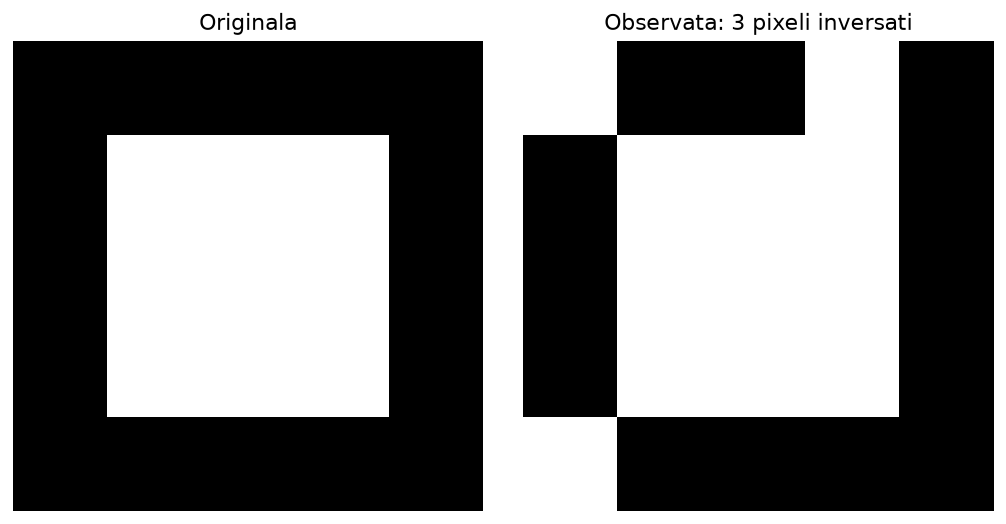

In [6]:
originala = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

observata = originala.copy()
random.seed(42)

pixeli_modificati = random.sample(range(25), 3)
for pixel in pixeli_modificati:
    linie = pixel // 5
    coloana = pixel % 5
    observata[linie, coloana] = 1 - observata[linie, coloana]

print("Imaginea originala:\n", originala)
print("Imaginea observata:\n", observata)
print("Pozitii modificate (numerotare de la 0):", pixeli_modificati)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(originala, cmap="gray", vmin=0, vmax=1,
           interpolation="nearest")
plt.title("Originala")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(observata, cmap="gray", vmin=0, vmax=1,
           interpolation="nearest")
plt.title("Observata: 3 pixeli inversati")
plt.axis("off")
plt.tight_layout()
plt.show()

**c) Graful pixelilor**

Numar pixeli: 25
Numar muchii: 40


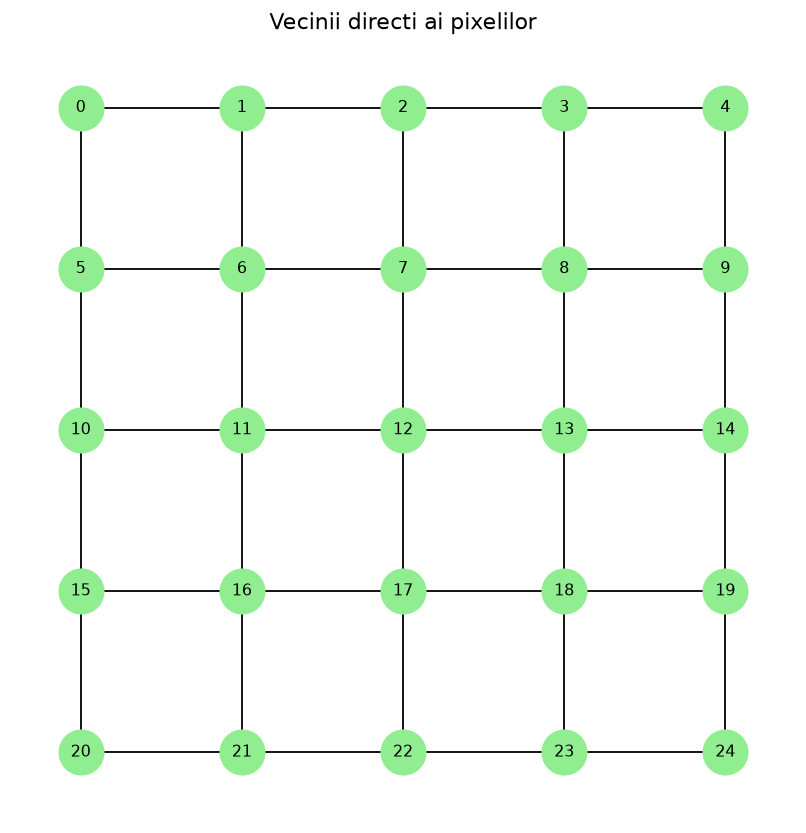

In [7]:
muchii = []
pozitii = {}
for linie in range(5):
    for coloana in range(5):
        pixel = linie * 5 + coloana
        pozitii[pixel] = (coloana, -linie)
        if coloana < 4:
            muchii.append((pixel, pixel + 1))
        if linie < 4:
            muchii.append((pixel, pixel + 5))

graf = nx.Graph()
graf.add_nodes_from(range(25))
graf.add_edges_from(muchii)
print("Numar pixeli:", graf.number_of_nodes())
print("Numar muchii:", graf.number_of_edges())
plt.figure(figsize=(6, 6))
nx.draw(graf, pos=pozitii, with_labels=True, node_color="lightgreen",
        node_size=600, font_size=9)
plt.title("Vecinii directi ai pixelilor")
plt.show()

**d)** Construim factorii in pgmpy si folosim ICM: pornim de la imaginea observata, comparam cele doua valori la fiecare pixel si schimbam doar daca energia scade. Repetam pana nu mai exista schimbari. La egalitate pastram valoarea actuala. ICM poate gasi un minim local, nu neaparat MAP global.

In [8]:
def construieste_model(observata, parametru_lambda):
    model = DiscreteMarkovNetwork(muchii)
    valori_observate = observata.flatten()

    for pixel in range(25):
        y = int(valori_observate[pixel])
        valori_factor = []
        for valoare in [0, 1]:
            valori_factor.append(
                math.exp(-parametru_lambda * (valoare - y) ** 2)
            )
        factor = DiscreteFactor([pixel], [2], valori_factor)
        model.add_factors(factor)

    valori_pereche = [[1, math.exp(-1)], [math.exp(-1), 1]]
    for primul, al_doilea in muchii:
        factor = DiscreteFactor([primul, al_doilea], [2, 2],
                                valori_pereche)
        model.add_factors(factor)
    return model

def energie(imagine, observata, parametru_lambda):
    x = imagine.flatten()
    y = observata.flatten()
    total = 0
    for pixel in range(25):
        total = total + parametru_lambda * (int(x[pixel]) - int(y[pixel])) ** 2
    for primul, al_doilea in muchii:
        total = total + (int(x[primul]) - int(x[al_doilea])) ** 2
    return total

def restaurare_icm(model, observata, parametru_lambda):

    x = observata.flatten().copy()
    y = observata.flatten()
    modificat = True

    while modificat:
        modificat = False
        for pixel in range(25):
            valoare_actuala = int(x[pixel])
            valoare_opusa = 1 - valoare_actuala

            cost_actual = parametru_lambda * (valoare_actuala - int(y[pixel])) ** 2
            cost_opus = parametru_lambda * (valoare_opusa - int(y[pixel])) ** 2

            for vecin in model.neighbors(pixel):
                cost_actual = cost_actual + (valoare_actuala - int(x[vecin])) ** 2
                cost_opus = cost_opus + (valoare_opusa - int(x[vecin])) ** 2

            if cost_opus < cost_actual:
                x[pixel] = valoare_opusa
                modificat = True

    return x.reshape(5, 5)

**e)** Comparam lambda = 0.3, 1 si 3, cu aceeasi imagine observata.

Model valid: True
lambda = 0.3 | pixeli gresiti = 11 | energie initiala = 17.0 | energie finala = 7.4
[[1 1 1 1 0]
 [1 1 1 1 0]
 [1 1 1 1 0]
 [1 1 1 1 0]
 [1 1 1 1 0]]
Model valid: True
lambda = 1 | pixeli gresiti = 1 | energie initiala = 17 | energie finala = 15
[[0 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
Model valid: True
lambda = 3 | pixeli gresiti = 3 | energie initiala = 17 | energie finala = 17
[[1 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 0 0 0 0]]


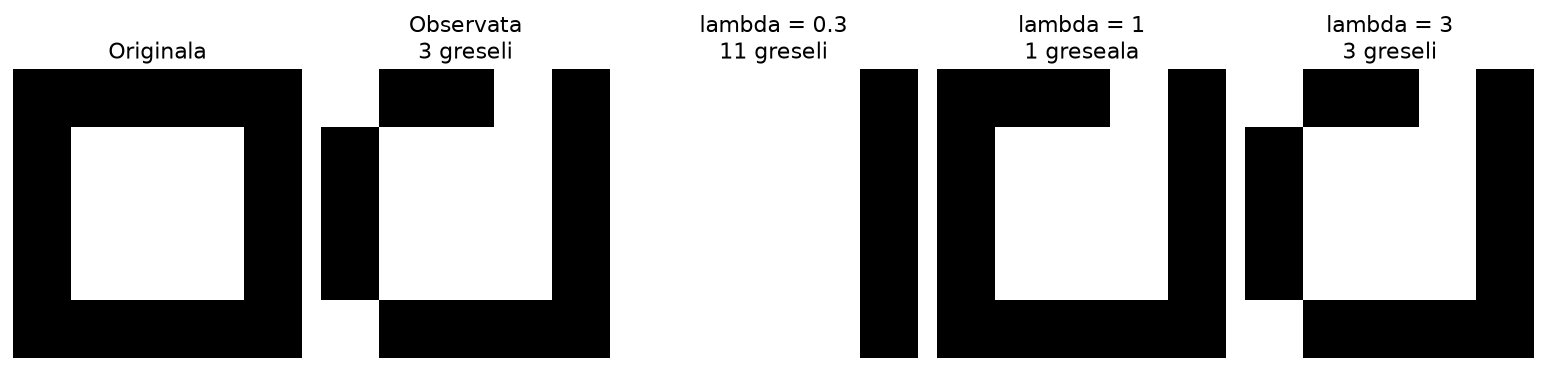

In [9]:
parametri = [0.3, 1, 3]
rezultate = []

for parametru_lambda in parametri:
    model = construieste_model(observata, parametru_lambda)
    print("Model valid:", model.check_model())
    restaurata = restaurare_icm(model, observata, parametru_lambda)
    rezultate.append(restaurata)

    greseli = int(np.sum(restaurata != originala))
    energie_initiala = energie(observata, observata, parametru_lambda)
    energie_finala = energie(restaurata, observata, parametru_lambda)
    print("lambda =", parametru_lambda, "| pixeli gresiti =", greseli,
          "| energie initiala =", energie_initiala,
          "| energie finala =", energie_finala)
    print(restaurata)

plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1)
plt.imshow(originala, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.title("Originala")
plt.axis("off")
plt.subplot(1, 5, 2)
plt.imshow(observata, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
plt.title("Observata\n3 greseli")
plt.axis("off")

for index in range(3):
    plt.subplot(1, 5, index + 3)
    plt.imshow(rezultate[index], cmap="gray", vmin=0, vmax=1,
               interpolation="nearest")
    greseli = int(np.sum(rezultate[index] != originala))
    eticheta = " greseala" if greseli == 1 else " greseli"
    plt.title("lambda = " + str(parametri[index]) + "\n"
              + str(greseli) + eticheta)
    plt.axis("off")

plt.tight_layout()
plt.show()

| Lambda | Pixeli gresiti |
|---|---:|
| Imagine observata | 3 |
| 0.3 | 11 |
| 1 | 1 |
| 3 | 3 |

Lambda mic favorizeaza netezirea, aici excesiva: regiunea alba se extinde.
Lambda mare favorizeaza fidelitatea fata de observatie si pastreaza zgomotul.
Pentru acest exemplu, lambda = 1 da cele mai putine erori.
Rezultatele depind si de initializarea si ordinea actualizarilor ICM.
Energia poate scadea fara sa scada si numarul de erori fata de originala.